# Dutch replication of the male abstraction bias (Fig. 1a)

The first of the cross-language replications in *The Male Abstraction Bias in Internet Culture and Large Language Models* (Supplementary Section "Replication of the text-based result in Dutch"): a gender axis is built from seed pairs in Dutch-trained word vectors (Eq. S1 of the supplement — the mean over seed pairs of unit(male) − unit(female), re-normalised), every rated word is scored by its cosine with the axis (positive = masculine), and the score is correlated with human concreteness ratings. A negative correlation means that more masculine words are more abstract.

**Norms.** `nl-brysbaert-2014.tsv` — Brysbaert, Stevens, De Deyne, Voorspoels & Storms (2014), *Acta Psychologica* 150, 80–84: concreteness (1–5) and age-of-acquisition ratings for Dutch words, collected with the same instructions and scale as the English Brysbaert et al. (2014) norms. The copy used is the one redistributed with the subs2vec package (van Paridon & Thompson 2021; `subs2vec/datasets/norms/nl-brysbaert-2014.tsv`), which holds 25,888 rows (25,881 distinct words with a concreteness rating); the authors' original release has 30,070 rows.

**Word vectors.** The static vector table of spaCy's `nl_core_news_lg` pipeline, version 3.8.0 (500,000 entries × 300 dimensions; fastText CBOW vectors trained by Explosion on the Dutch portions of OSCAR Common Crawl and Wikipedia). Install with

```
pip install spacy wordfreq
pip install https://github.com/explosion/spacy-models/releases/download/nl_core_news_lg-3.8.0/nl_core_news_lg-3.8.0-py3-none-any.whl
```

**Seed pairs.** Primary (chosen before any result was seen): man/vrouw, jongen/meisje, mannelijk/vrouwelijk, vader/moeder, broer/zus — the paper's five English pairs with the two pronoun pairs replaced by kinship pairs, because *zij* also means *they* and *haar* also means *hair*. Extended: the primary pairs plus zoon/dochter, oom/tante, koning/koningin, heer/dame, opa/oma. Pronoun set (reported to show the consequence of the ambiguity): man/vrouw, hij/zij, hem/haar, mannelijk/vrouwelijk, jongen/meisje.

**Controls.** Word frequency is the Zipf-scaled frequency of the `wordfreq` library (Dutch list; words without an entry are treated as missing), length is the number of characters, and age of acquisition comes from the same norms.

**Outputs** (identical in content to the files committed alongside this notebook, in `results_nl/`): `stats_nl.csv` (every specification for each seed set), `deciles_nl.csv`, `pole_sensitivity_nl.csv` (seed-pair sensitivity with the extreme words), `scores_nl.csv` (per-word gender scores), `seeds_nl.json`, `validation_nl.csv` (held-out gendered pairs), and `figS_dutch_replication.{png,pdf}` (Supplementary Fig.).

**Requirements:** Python 3, `numpy pandas scipy statsmodels matplotlib wordfreq spacy` and the model above (`pip install -r requirements.txt`).

In [1]:
# ---------------------------------------------------------------- configuration
from pathlib import Path
import re

BASE  = Path.cwd()                                  # the folder holding this notebook and the norms file
NORMS = BASE / "nl-brysbaert-2014.tsv"
OUT   = BASE / "results_nl"; OUT.mkdir(exist_ok=True)
assert NORMS.exists(), f"missing file: {NORMS}"

LANGNAME, SCALE, SPACY_MODEL, WORDFREQ_LANG = "Dutch", "1–5", "nl_core_news_lg", "nl"
SEEDS = {
    "primary":  [("man", "vrouw"), ("jongen", "meisje"), ("mannelijk", "vrouwelijk"), ("vader", "moeder"), ("broer", "zus")],
    "extended": [("man", "vrouw"), ("jongen", "meisje"), ("mannelijk", "vrouwelijk"), ("vader", "moeder"), ("broer", "zus"),
                 ("zoon", "dochter"), ("oom", "tante"), ("koning", "koningin"), ("heer", "dame"), ("opa", "oma")],
    "pronoun":  [("man", "vrouw"), ("hij", "zij"), ("hem", "haar"), ("mannelijk", "vrouwelijk"), ("jongen", "meisje")],
}
# gendered word pairs not used as primary seeds: a valid axis orders the male above the female member
VALIDATION = [("koning", "koningin"), ("oom", "tante"), ("zoon", "dochter"), ("acteur", "actrice"), ("heer", "dame"), ("opa", "oma"),
              ("neef", "nicht"), ("prins", "prinses"), ("bruidegom", "bruid"), ("meneer", "mevrouw"), ("kerel", "meid"), ("monnik", "non"),
              ("held", "heldin"), ("vriend", "vriendin"), ("echtgenoot", "echtgenote"), ("leraar", "lerares"), ("zanger", "zangeres"),
              ("weduwnaar", "weduwe"), ("stiefvader", "stiefmoeder"), ("grootvader", "grootmoeder"), ("papa", "mama"), ("jongens", "meisjes"),
              ("mannen", "vrouwen"), ("vaders", "moeders"), ("broers", "zussen"), ("hij", "zij"), ("hem", "haar")]
# crude 'lexically gendered' filter (gendered morphemes, kinship and role stems), used in one exclusion check
GENDERED_RE = re.compile(r"(?:man$|mannen|vrouw|jongen|meisje|vader|moeder|broer|zus$|zuster|heer$|dame|koning|prins|mannelijk|vrouwelijk|-in$|ster$|es$|vrouwelijk|mama|papa|oma|opa|tante|oom|neef|nicht|dochter|zoon|echtgeno|weduw|bruid|bruidegom|non$|monnik|priester|meid|knaap|kerel|vent$|wijf|gast$|jongen|meisje|juffrouw|mevrouw|mijnheer|meneer)")
print("norms:", NORMS.name, "| outputs:", OUT.name)

norms: nl-brysbaert-2014.tsv | outputs: results_nl


In [2]:
# ---------------------------------------------------------------- imports and helpers
import json
import numpy as np, pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)

def unit(v):
    n = np.linalg.norm(v); return v / n if n > 0 else v

_warned = set()
def gender_axis(lookup, pairs):
    # Eq. S1: mean over seed pairs of unit(male) - unit(female), re-normalised
    diffs, used = [], []
    for m, f in pairs:
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None:
            if (m, f) not in _warned: print(f"   seed pair missing in the vectors: ({m}, {f})"); _warned.add((m, f))
            continue
        diffs.append(unit(vm) - unit(vf)); used.append((m, f))
    if not diffs: raise RuntimeError("no seed pairs available in the vectors")
    return unit(np.mean(diffs, axis=0)), used

def score_terms(lookup, axis, words):
    g = np.full(len(words), np.nan)
    for i, w in enumerate(words):
        v = lookup(w)
        if v is not None: g[i] = float(unit(v) @ axis)
    return g

def fisher_ci(r, n):
    if n < 4 or abs(r) >= 1: return (np.nan, np.nan)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3); q = stats.norm.ppf(0.975)
    return tuple(np.tanh([z - q * se, z + q * se]))

def zs(x):
    x = np.asarray(x, float); return (x - np.nanmean(x)) / np.nanstd(x)

def describe(df, label):
    d = df.dropna(subset=["gender", "conc"])
    r, p = stats.pearsonr(d.gender, d.conc); lo, hi = fisher_ci(r, len(d)); rho, _ = stats.spearmanr(d.gender, d.conc)
    return dict(specification=label, r=r, ci_lo=lo, ci_hi=hi, p=p, rho=rho, n=len(d))

def ols_beta(df, controls, label):
    # standardised coefficient on concreteness (HC1 SEs) in a regression of z(gender) on z(concreteness) + controls
    cols = ["conc"] + controls
    d = df.dropna(subset=["gender"] + cols)
    X = sm.add_constant(np.column_stack([zs(d[c]) for c in cols]))
    res = sm.OLS(zs(d.gender), X).fit(cov_type="HC1"); ci = res.conf_int()[1]
    return dict(specification=label, r=res.params[1], ci_lo=ci[0], ci_hi=ci[1], p=res.pvalues[1], rho=np.nan, n=len(d))

def deciles(df):
    d = df.dropna(subset=["gender", "conc"]).copy()
    d["decile"] = pd.qcut(d.gender.rank(method="first"), 10, labels=range(1, 11)).astype(int)
    return d.groupby("decile").conc.agg(["mean", "count"]).reset_index()

def validation(lookup, axis, used):
    rows = []
    for m, f in VALIDATION:
        if (m, f) in used: continue
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None: continue
        sm_, sf_ = float(unit(vm) @ axis), float(unit(vf) @ axis)
        rows.append(dict(male=m, female=f, score_male=sm_, score_female=sf_, male_above_female=sm_ > sf_))
    return pd.DataFrame(rows)

## 1. Norms

In [3]:
from wordfreq import zipf_frequency
raw = pd.read_csv(NORMS, sep="\t")
norms = raw.rename(columns={"concreteness": "conc", "age of acquisition": "aoa"})
norms["word"] = norms["word"].astype(str).str.strip()
norms["conc"] = pd.to_numeric(norms["conc"], errors="coerce")
norms = norms.dropna(subset=["conc"]).drop_duplicates("word").reset_index(drop=True)   # keep the first entry of a repeated form
norms["length"] = norms["word"].str.len()
norms["logfreq"] = [zipf_frequency(w, WORDFREQ_LANG) for w in norms["word"]]
norms.loc[norms["logfreq"] <= 0, "logfreq"] = np.nan                                   # no wordfreq entry -> missing
print(f"{len(raw):,} rows; {len(norms):,} distinct rated words; concreteness mean {norms.conc.mean():.2f} (sd {norms.conc.std():.2f}) on a {SCALE} scale; "
      f"{norms.logfreq.notna().sum():,} with a frequency, {norms.aoa.notna().sum():,} with an AoA rating")
norms.sample(8, random_state=1)

25,888 rows; 25,881 distinct rated words; concreteness mean 2.93 (sd 0.99) on a 1–5 scale; 24,101 with a frequency, 25,862 with an AoA rating


,word,aoa,conc,length,logfreq
16754,plaveien,12.24,3.13,8,1.68
308,aardbol,7.70,4.33,7,3.04
17046,postuum,14.38,1.23,7,2.98
7511,gekromd,9.33,3.87,7,2.13
19174,secularisme,14.69,1.50,11,2.50
2028,begonia,10.82,4.92,7,1.97
21515,toedoen,8.83,2.80,7,3.64
11435,koolwitje,9.36,4.29,9,1.99


## 2. Dutch word vectors (spaCy `nl_core_news_lg`)

In [4]:
import spacy
nlp = spacy.load(SPACY_MODEL, exclude=["tagger", "parser", "ner", "lemmatizer", "attribute_ruler", "morphologizer", "senter"])
print(SPACY_MODEL, "v" + nlp.meta["version"], "| vectors", nlp.vocab.vectors.shape, "| sources:", [s.get("name") for s in nlp.meta.get("sources", [])])

def lookup(w):
    for cand in (w, w.lower()):
        lex = nlp.vocab[cand]
        if lex.has_vector and lex.vector_norm > 0: return np.asarray(lex.vector, dtype=np.float32)
    return None

covered = norms.word.map(lambda w: lookup(w) is not None)
print(f"{covered.sum():,} of {len(norms):,} rated words ({covered.mean():.1%}) have a vector")
missing = sorted({p for s in SEEDS.values() for p in s if lookup(p[0]) is None or lookup(p[1]) is None})
print("seed pairs missing from the vectors:", missing or "none")

nl_core_news_lg v3.8.0 | vectors (500000, 300) | sources: ['UD Dutch LassySmall v2.8', 'Dutch NER Annotations for UD LassySmall', 'UD Dutch Alpino v2.8', 'Explosion fastText Vectors (cbow, OSCAR Common Crawl + Wikipedia)']


23,758 of 25,881 rated words (91.8%) have a vector
seed pairs missing from the vectors: none


## 3. Gender scores and the main test

For each seed set: gender scores for every rated word, the held-out gendered-pair check, and the association with concreteness under every specification reported in the Supplementary Table — Pearson's r with Fisher 95 % CI (and Spearman's ρ) for all words, after excluding lexically gendered words and seeds, and after excluding the 5 % and 10 % most gendered words; HC1-robust standardised β with no controls, with log frequency, with length, with both, and with frequency, length and age of acquisition; and the correlation within each quintile of word frequency. A negative sign means that more masculine words are more abstract.

In [5]:
rows, dec_tables, seeds_used, scores, VAL = [], [], {}, norms[["word", "conc"]].copy(), []
for pset, pairs in SEEDS.items():
    axis, used = gender_axis(lookup, pairs); seeds_used[pset] = used
    g = score_terms(lookup, axis, norms.word.tolist())
    df = norms.copy(); df["gender"] = g; scores[f"gender::{pset}"] = g
    V = validation(lookup, axis, used); V["seeds"] = pset; VAL.append(V)
    print(f"seeds={pset}: {len(used)}/{len(pairs)} pairs; {int(np.isfinite(g).sum()):,}/{len(df):,} words scored; "
          f"held-out gendered pairs ordered male > female: {int(V.male_above_female.sum())}/{len(V)}")
    R = [describe(df, "all terms (no controls)")]
    seedset = {w for p in used for w in p}
    R.append(describe(df[~(df.word.str.contains(GENDERED_RE) | df.word.isin(seedset))], "excl. lexically gendered terms + seeds"))
    for q in (0.05, 0.10):
        thr = df.gender.abs().quantile(1 - q); R.append(describe(df[df.gender.abs() < thr], f"excl. {int(q*100)}% most gendered terms"))
    R.append(ols_beta(df, [], "OLS: no controls"))
    R.append(ols_beta(df, ["logfreq"], "OLS: + log frequency"))
    R.append(ols_beta(df, ["length"], "OLS: + length"))
    R.append(ols_beta(df, ["logfreq", "length"], "OLS: + frequency + length"))
    R.append(ols_beta(df, ["logfreq", "length", "aoa"], "OLS: + frequency + length + AoA"))
    dq = df.dropna(subset=["logfreq", "gender"]).copy()
    dq["fq"] = pd.qcut(dq.logfreq.rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
    for k in range(1, 6):
        R.append(describe(dq[dq.fq == k], f"frequency quintile {k}" + (" (least frequent)" if k == 1 else " (most frequent)" if k == 5 else "")))
    for r_ in R: r_.update(seeds=pset)
    rows += R
    dd = deciles(df); dd["seeds"] = pset; dec_tables.append(dd)

S = pd.DataFrame(rows)[["seeds", "specification", "r", "ci_lo", "ci_hi", "p", "rho", "n"]]
S.insert(0, "model", SPACY_MODEL); S.insert(0, "language", LANGNAME)
DEC = pd.concat(dec_tables, ignore_index=True); VAL = pd.concat(VAL, ignore_index=True)
S.drop(columns=["language", "model"]).round(4)

seeds=primary: 5/5 pairs; 23,758/25,881 words scored; held-out gendered pairs ordered male > female: 27/27


seeds=extended: 10/10 pairs; 23,758/25,881 words scored; held-out gendered pairs ordered male > female: 22/22


seeds=pronoun: 5/5 pairs; 23,758/25,881 words scored; held-out gendered pairs ordered male > female: 25/25


,seeds,specification,r,ci_lo,ci_hi,p,rho,n
0,primary,all terms (no controls),-0.2677,-0.2795,-0.2558,0.0,-0.2488,23758
1,primary,excl. lexically gendered terms + seeds,-0.2678,-0.2798,-0.2558,0.0,-0.2465,23062
2,primary,excl. 5% most gendered terms,-0.2808,-0.2928,-0.2687,0.0,-0.2593,22570
3,primary,excl. 10% most gendered terms,-0.2837,-0.2960,-0.2713,0.0,-0.2640,21382
4,primary,OLS: no controls,-0.2677,-0.2798,-0.2556,0.0,NaN,23758
5,primary,OLS: + log frequency,-0.2688,-0.2812,-0.2565,0.0,NaN,23407
6,primary,OLS: + length,-0.2351,-0.2472,-0.2231,0.0,NaN,23758
7,primary,OLS: + frequency + length,-0.2308,-0.2432,-0.2184,0.0,NaN,23407
8,primary,OLS: + frequency + length + AoA,-0.2445,-0.2582,-0.2308,0.0,NaN,23398
9,primary,frequency quintile 1 (least frequent),-0.2356,-0.2625,-0.2083,0.0,-0.2234,4682


## 4. Decile pattern and figure (Supplementary Fig.: Dutch)

Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):


seeds,extended,primary,pronoun
decile,,,
1,3.586,3.573,2.625
2,3.302,3.319,2.608
3,3.151,3.079,2.721
4,3.045,2.953,2.816
5,2.881,2.837,2.905
6,2.799,2.771,2.968
7,2.711,2.704,3.047
8,2.634,2.690,3.137
9,2.600,2.676,3.227


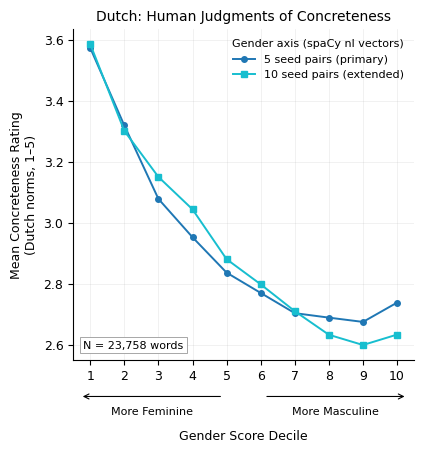

In [6]:
print("Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):")
display(DEC.pivot_table(index="decile", columns="seeds", values="mean").round(3))

n_words = int(S[(S.seeds == "primary") & (S.specification == "all terms (no controls)")].n.iloc[0])
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(4.4, 4.3))
for pset, label, col, mk in [("primary", "5 seed pairs (primary)", "#1f77b4", "o"), ("extended", "10 seed pairs (extended)", "#17becf", "s")]:
    d = DEC[DEC.seeds == pset].sort_values("decile"); ax.plot(d.decile, d["mean"], marker=mk, ms=4, lw=1.4, color=col, label=label)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.5, 10.5)
ax.set_ylabel(f"Mean Concreteness Rating\n({LANGNAME} norms, {SCALE})")
ax.set_title(f"{LANGNAME}: Human Judgments of Concreteness", fontsize=10); ax.grid(alpha=0.25, lw=0.5)
ax.text(0.03, 0.03, f"N = {n_words:,} words", ha="left", va="bottom", transform=ax.transAxes, fontsize=8, bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6", lw=0.6))
ax.legend(loc="upper right", fontsize=8, frameon=False, title="Gender axis (spaCy nl vectors)", title_fontsize=8)
ax.set_xlabel("Gender Score Decile", labelpad=34)
ax.annotate("", xy=(0.02, -0.11), xytext=(0.44, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.annotate("", xy=(0.98, -0.11), xytext=(0.56, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.text(0.23, -0.14, "More Feminine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
ax.text(0.77, -0.14, "More Masculine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
for ext in ("png", "pdf"): fig.savefig(OUT / f"figS_dutch_replication.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## 5. Sensitivity to the seed pairs

The primary and extended sets, each leave-one-pair-out axis from the primary set, every single pair, the pronoun set and its pronoun pairs on their own, and the first principal component of the ten unit-normalised pair differences of the extended set (uncentred SVD, sign-aligned with their mean) — each with the most feminine and most masculine words under the axis, which is how the contaminated pronoun axes (*zij* = they, *haar* = hair) show themselves.

In [7]:
prim, ext = SEEDS["primary"], SEEDS["extended"]
specs = {"primary set (5 pairs)": prim, "extended set (10 pairs)": ext}
for p in prim: specs[f"primary minus {p[0]}/{p[1]}"] = [q for q in prim if q != p]
for p in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
specs["pronoun set"] = SEEDS["pronoun"]
for p in SEEDS["pronoun"]:
    if p not in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
PS = []
for label, pairs in specs.items():
    axis, used = gender_axis(lookup, pairs)
    g = score_terms(lookup, axis, norms.word.tolist()); ok = np.isfinite(g)
    r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
    d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
    PS.append(dict(specification=label, n_pairs=len(used), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()),
                   most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
D = np.vstack([unit(unit(lookup(m)) - unit(lookup(f))) for m, f in ext])
U, s, Vt = np.linalg.svd(D, full_matrices=False); pc1 = Vt[0]; pc1 = pc1 if D.mean(0) @ pc1 > 0 else -pc1
g = score_terms(lookup, unit(pc1), norms.word.tolist()); ok = np.isfinite(g)
r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
PS.append(dict(specification=f"PC1 of extended set (var. expl. {s[0]**2/(s**2).sum():.2f}; loadings {np.round(D@pc1,2).tolist()})",
               n_pairs=len(D), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()), most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
PS = pd.DataFrame(PS)
PS[["specification", "n_pairs", "r", "ci_lo", "ci_hi", "n", "most_female", "most_male"]].round(3)

,specification,n_pairs,r,ci_lo,ci_hi,n,most_female,most_male
0,primary set (5 pairs),5,-0.268,-0.279,-0.256,23758,"babydoll, bruidsmeisje, lesbienne, brunette, topless, lingerie, seksbom, bikini","aanvoerder, voorman, voorganger, manschappen, bevelhebber, tegenstander, loo..."
1,extended set (10 pairs),10,-0.292,-0.304,-0.280,23758,"babydoll, brunette, blondine, lingerie, tienermeisje, seksbom, stoeipoes, me...","leenheer, voorman, aanvoerder, veldheer, hopman, rentmeester, landheer, kolonel"
2,primary minus man/vrouw,4,-0.339,-0.350,-0.327,23758,"babydoll, brunette, topless, bruidsmeisje, pinup, meisje, bikini, lesbienne","aanvoerder, voorman, voorganger, gebroeders, meesterzet, oudgediende, veedri..."
3,primary minus jongen/meisje,4,-0.148,-0.160,-0.135,23758,"babydoll, lingerie, seksbom, brunette, lesbienne, topless, bikini, borstvoeding","voorman, veldheer, kompaan, aanvoerder, opportunist, zetbaas, bevelhebber, r..."
4,primary minus mannelijk/vrouwelijk,4,-0.288,-0.299,-0.276,23758,"lesbienne, babydoll, topless, brunette, bruidsmeisje, seksbom, poesje, tiene...","aanvoerder, voorman, voorganger, veedrijver, oudgediende, manschappen, meest..."
5,primary minus vader/moeder,4,-0.229,-0.241,-0.216,23758,"bruidsmeisje, topless, babydoll, lesbienne, brunette, boudoir, actrice, beauty","manschappen, aanvoerder, tegenstander, loopjongen, verschalken, belagen, inv..."
6,primary minus broer/zus,4,-0.226,-0.238,-0.214,23758,"bruidsmeisje, babydoll, lesbienne, brunette, tienermeisje, lingerie, topless...","aanvoerder, manschappen, ploegbaas, opportunist, voorman, landmeter, duivenm..."
7,single pair man/vrouw,1,0.239,0.227,0.251,23758,"moederschap, seksualiteit, masturbatie, zwangerschap, echtgenote, pornografi...","prutser, malloot, mafkees, hooligan, pakweg, flik, idioot, gozer"
8,single pair jongen/meisje,1,-0.288,-0.300,-0.277,23758,"meisje, bruidsmeisje, tienermeisje, poesje, blondje, kiekje, slipje, roodharig","koeren, zieden, voortrekken, venten, poeieren, hokken, manschappen, onderwaa..."
9,single pair mannelijk/vrouwelijk,1,0.042,0.029,0.054,23758,"ontwerpster, kunstenares, styliste, schrijfster, presentatrice, feestjurk, t...","kapotslaan, stompen, blaffer, hoorndol, hooivork, afsnauwen, stokdoof, afsto..."


## 6. Save everything

In [8]:
S.to_csv(OUT / "stats_nl.csv", index=False)
DEC.to_csv(OUT / "deciles_nl.csv", index=False)
PS.to_csv(OUT / "pole_sensitivity_nl.csv", index=False)
scores.to_csv(OUT / "scores_nl.csv", index=False)
VAL.to_csv(OUT / "validation_nl.csv", index=False)
json.dump(seeds_used, open(OUT / "seeds_nl.json", "w", encoding="utf8"), ensure_ascii=False, indent=1)
print("written to", OUT.name)
for f in sorted(OUT.iterdir()): print("  ", f.name)

written to results_nl
   deciles_nl.csv
   figS_dutch_replication.pdf
   figS_dutch_replication.png
   pole_sensitivity_nl.csv
   scores_nl.csv
   seeds_nl.json
   stats_nl.csv
   validation_nl.csv
